# Is Team Efficiency Repeatable? Year-over-Year Stability of Rushing and Passing EPA

**Follow-up to the first two notebooks.** Earlier analyses showed that passing efficiency is more strongly associated with win percentage than rushing efficiency, both overall and in neutral game situations. A related question is whether each metric is *repeatable*: if a team's number this season says little about next season, it is hard to rely on for planning or evaluation.

**Questions:** (1) How well does a team's rushing and passing EPA in one season predict the same metric the following season? (2) Which one better predicts next season's win percentage? (3) Does restricting to neutral game situations change stability?

## 1. Setup: team-season table and season-to-season pairs

For each team and season I calculate EPA per rush, EPA per pass and win percentage. Each season's row is then matched with the same team's numbers from the *following* season. This gives 96 pairs (32 teams x 3 transitions: 2022 to 2023, 2023 to 2024, 2024 to 2025).

In [1]:
import os
import nflreadpy as nfl
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

seasons = [2022, 2023, 2024, 2025]
pbp = nfl.load_pbp(seasons).to_pandas()
reg = pbp[(pbp["season_type"] == "REG") & pbp["posteam"].notna() & pbp["epa"].notna()].copy()

# Win percentage by team-season
sched = nfl.load_schedules(seasons).to_pandas()
sched = sched[(sched["game_type"] == "REG") & sched["result"].notna()]
home = sched[["season", "home_team", "home_score", "away_score"]].set_axis(["season", "posteam", "pf", "pa"], axis=1)
away = sched[["season", "away_team", "away_score", "home_score"]].set_axis(["season", "posteam", "pf", "pa"], axis=1)
games = pd.concat([home, away])
games["win"] = (games["pf"] > games["pa"]).astype(float)
games.loc[games["pf"] == games["pa"], "win"] = 0.5
rec = games.groupby(["season", "posteam"]).agg(win_pct=("win", "mean")).reset_index()

def team_season(df):
    rush = (df[(df["rush_attempt"] == 1) & (df["qb_scramble"] == 0)]
            .groupby(["season", "posteam"]).agg(rush_epa=("epa", "mean")).reset_index())
    pas = (df[df["pass"] == 1]
           .groupby(["season", "posteam"]).agg(pass_epa=("epa", "mean")).reset_index())
    return rush.merge(pas, on=["season", "posteam"]).merge(rec, on=["season", "posteam"])

def make_pairs(ts):
    """Attach each team's NEXT-season numbers to its current-season row."""
    nxt = ts[["season", "posteam", "rush_epa", "pass_epa", "win_pct"]].copy()
    nxt["season"] = nxt["season"] - 1
    nxt = nxt.rename(columns={"rush_epa": "rush_epa_next",
                              "pass_epa": "pass_epa_next",
                              "win_pct": "win_pct_next"})
    return ts.merge(nxt, on=["season", "posteam"])

ts = team_season(reg)
pairs = make_pairs(ts)
print(len(ts), len(pairs))
pairs.head()

128 96


,season,posteam,rush_epa,pass_epa,win_pct,rush_epa_next,pass_epa_next,win_pct_next
0,2022,ARI,-0.056647,-0.059355,0.235294,-0.013912,-0.064265,0.235294
1,2022,ATL,0.014081,0.004493,0.411765,-0.146979,-0.018904,0.411765
2,2022,BAL,0.035132,-0.016055,0.588235,-0.012431,0.104858,0.764706
3,2022,BUF,-0.086125,0.184538,0.812500,0.003784,0.142948,0.647059
4,2022,CAR,-0.002062,-0.050381,0.411765,-0.117742,-0.127811,0.117647


In [2]:
print("Year-to-year correlation (same metric, consecutive seasons)")
print("  Rushing EPA:", round(pairs["rush_epa"].corr(pairs["rush_epa_next"]), 3))
print("  Passing EPA:", round(pairs["pass_epa"].corr(pairs["pass_epa_next"]), 3))
print("  Win %:      ", round(pairs["win_pct"].corr(pairs["win_pct_next"]), 3))

print()
for s, g in pairs.groupby("season"):
    print(f"{s} to {s+1}  rush: {g['rush_epa'].corr(g['rush_epa_next']):.3f}   pass: {g['pass_epa'].corr(g['pass_epa_next']):.3f}")

Year-to-year correlation (same metric, consecutive seasons)
  Rushing EPA: 0.245
  Passing EPA: 0.423
  Win %:       0.323

2022 to 2023  rush: 0.294   pass: 0.503
2023 to 2024  rush: 0.197   pass: 0.448
2024 to 2025  rush: 0.357   pass: 0.350


## 2. Year-to-year stability

| Season pair | Rushing EPA (r) | Passing EPA (r) |
|---|---|---|
| 2022 to 2023 | 0.29 | 0.50 |
| 2023 to 2024 | 0.20 | 0.45 |
| 2024 to 2025 | 0.36 | 0.35 |
| **All pairs** | **0.25** | **0.42** |

**Interpretation:** Passing efficiency carries over from one season to the next noticeably better than rushing efficiency (about 18% of next season's variation explained vs. about 6%). The pattern was clear in two of three season pairs; in 2024 to 2025 the two were nearly equal. Each pair has only 32 teams, so single-pair results are noisy.

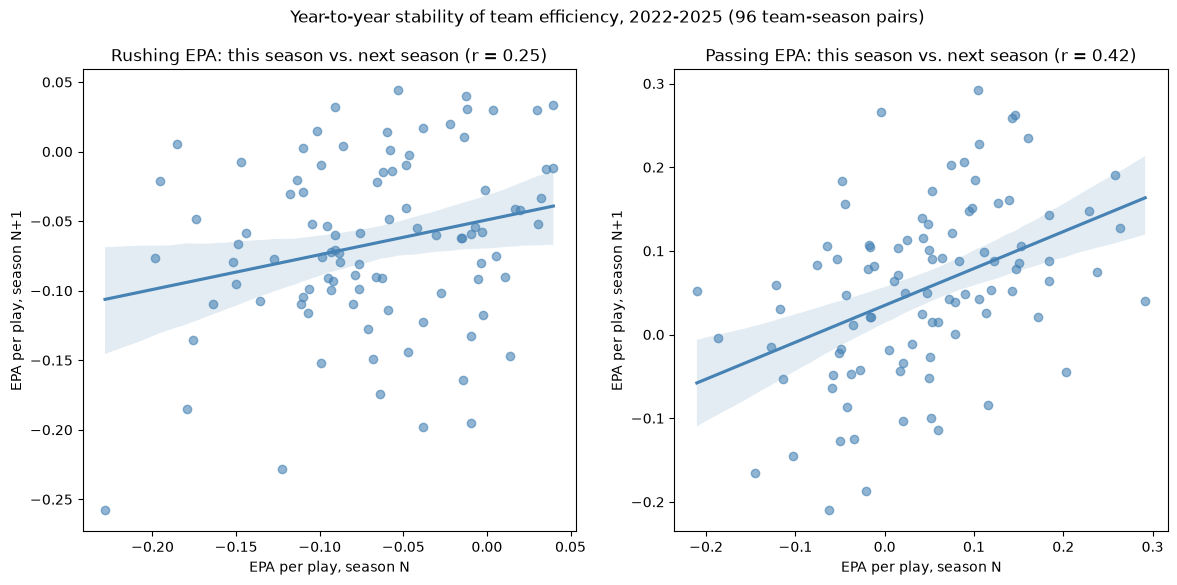

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, cur, nxt, title in [(axes[0], "rush_epa", "rush_epa_next", "Rushing EPA"),
                            (axes[1], "pass_epa", "pass_epa_next", "Passing EPA")]:
    sns.regplot(data=pairs, x=cur, y=nxt, color="steelblue", ax=ax, scatter_kws={"alpha": 0.6})
    r = pairs[cur].corr(pairs[nxt])
    ax.set_title(f"{title}: this season vs. next season (r = {r:.2f})")
    ax.set_xlabel("EPA per play, season N")
    ax.set_ylabel("EPA per play, season N+1")

fig.suptitle("Year-to-year stability of team efficiency, 2022-2025 (96 team-season pairs)")
os.makedirs("images", exist_ok=True)
plt.savefig("images/year_over_year_stability.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading the chart:** Each dot is one team, with this season's EPA on the x-axis and the same team's EPA the following season on the y-axis. A tight diagonal band would mean a stable metric. The rushing cloud (left) is more scattered and its trend line is flatter than the passing cloud (right).

In [4]:
print("Predicting NEXT season's win % from THIS season's...")
print("  Rushing EPA:", round(pairs["rush_epa"].corr(pairs["win_pct_next"]), 3))
print("  Passing EPA:", round(pairs["pass_epa"].corr(pairs["win_pct_next"]), 3))
print("  Win % (baseline):", round(pairs["win_pct"].corr(pairs["win_pct_next"]), 3))

Predicting NEXT season's win % from THIS season's...
  Rushing EPA: 0.123
  Passing EPA: 0.358
  Win % (baseline): 0.323


## 3. Does this season's efficiency predict next season's wins?

| Predictor (season N) | Correlation with win % (season N+1) |
|---|---|
| Rushing EPA | 0.12 |
| Passing EPA | 0.36 |
| Win % (baseline) | 0.32 |

**Interpretation:** Last season's rushing efficiency was a weak predictor of next season's record. Passing efficiency was slightly higher than the team's own prior win percentage, but the difference is small relative to the sample (96 overlapping pairs), so I treat them as roughly equivalent rather than claiming passing EPA is the better predictor.

In [5]:
neutral = reg[reg["wp"].between(0.2, 0.8) & (reg["half_seconds_remaining"] > 120) & (reg["qtr"] <= 4)]
pairs_neu = make_pairs(team_season(neutral))

print("Year-to-year stability, neutral situations only")
print("  Rushing EPA:", round(pairs_neu["rush_epa"].corr(pairs_neu["rush_epa_next"]), 3))
print("  Passing EPA:", round(pairs_neu["pass_epa"].corr(pairs_neu["pass_epa_next"]), 3))

Year-to-year stability, neutral situations only
  Rushing EPA: 0.172
  Passing EPA: 0.339


## 5. Conclusions and limitations

**Conclusion:** Passing efficiency is the more repeatable of the two metrics (r = 0.42 vs. 0.25 year to year), and last season's passing EPA predicted next season's win percentage about as well as last season's record did (r = 0.36 vs. 0.32). Last season's rushing EPA was a weak predictor (r = 0.12). Filtering to neutral situations did not improve stability for either metric.

**Limitations**
- Only three season-to-season transitions, with 96 pairs; the 2023 data appears in two pairs, so the pairs are not fully independent.
- Roster, coaching and quarterback changes affect both metrics and are not modeled. Low stability does not mean rushing skill is meaningless, only that this team-level number moves around.
- The difference between 0.36 (passing EPA) and 0.32 (win %) is not tested for statistical significance and should not be over-read.
- The explanation for lower neutral-situation stability (smaller samples) is a hypothesis, not a result.

**Next steps:** extend the window to 2018-2025 for more pairs, and test whether differences between correlations are statistically distinguishable (for example with bootstrapped confidence intervals).